# Exploring the OpenBookQA data

> Assuming "HandbookQA" means **OpenBookQA** (`allenai/openbookqa`), the dataset this repo targets.

A quick look at the raw dataset and at how this repo turns each row into a
reasoning prompt (`reasoning_trajectories.datasets.OpenBookQA`).

Needs: `pip install -r ../requirements.txt` (at least `datasets`, `pandas`, `matplotlib`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

pd.set_option("display.max_colwidth", 120)

C:\Users\cfavr\PycharmProjects\reasoningvalidation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the splits

Config `main` has the question + choices + answer key. Config `additional` adds
`fact1` (the gold science fact) and crowd metadata.

In [2]:
main = {s: load_dataset("allenai/openbookqa", "main", split=s) for s in ["train", "validation", "test"]}
additional = {s: load_dataset("allenai/openbookqa", "additional", split=s) for s in ["train", "validation", "test"]}

pd.DataFrame({
    "main": {s: len(d) for s, d in main.items()},
    "additional": {s: len(d) for s, d in additional.items()},
})

C:\Users\cfavr\PycharmProjects\reasoningvalidation\.venv\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\cfavr\.cache\huggingface\hub\datasets--allenai--openbookqa. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating test split: 100%|██████████| 500/500 [00:00<00:00, 113734.58 examples/s]


,main,additional
train,4957,4957
validation,500,500
test,500,500


In [3]:
print("main features:\n", main["train"].features, "\n")
print("additional-only columns:", sorted(set(additional["train"].column_names) - set(main["train"].column_names)))

main features:
 {'id': Value('string'), 'question_stem': Value('string'), 'choices': {'text': List(Value('string')), 'label': List(Value('string'))}, 'answerKey': Value('string')} 

additional-only columns: ['clarity', 'fact1', 'humanScore', 'turkIdAnonymized']


In [4]:
# one raw row
additional["validation"][0]

{'id': '8-376',
 'question_stem': 'Frilled sharks and angler fish live far beneath the surface of the ocean, which is why they are known as',
 'choices': {'text': ['Deep sea animals',
   'fish',
   'Long Sea Fish',
   'Far Sea Animals'],
  'label': ['A', 'B', 'C', 'D']},
 'answerKey': 'A',
 'fact1': 'deep sea animals live deep in the ocean',
 'humanScore': 0.800000011920929,
 'clarity': 1.7999999523162842,
 'turkIdAnonymized': 'bdb4135787'}

## 2. Peek at examples

In [5]:
def to_frame(ds):
    rows = []
    for r in ds:
        labels = list(r["choices"]["label"])
        texts = list(r["choices"]["text"])
        key = r["answerKey"]
        rows.append({
            "id": r["id"],
            "question_stem": r["question_stem"],
            "n_choices": len(texts),
            "labels": "".join(labels),
            "answerKey": key,
            "answer_text": texts[labels.index(key)] if key in labels else None,
            "fact1": r.get("fact1"),
        })
    return pd.DataFrame(rows)

val = to_frame(additional["validation"])
val.head(8)

,id,question_stem,n_choices,labels,answerKey,answer_text,fact1
0,8-376,"Frilled sharks and angler fish live far beneath the surface of the ocean, which is why they are known as",4,ABCD,A,Deep sea animals,deep sea animals live deep in the ocean
1,7-57,"Gas can fill any container it is given, and liquid",4,ABCD,D,uses what it needs,Matter in the liquid phase has definite volume
2,7-1024,"When birds migrate south for the winter, they do it because",4,ABCD,A,they are genetically called to,migration is an instinctive behavior
3,959,If a person walks in the opposite direction of a compass arrow they are walking,4,ABCD,D,south,a compass is a kind of tool for determining direction by pointing north
4,9-241,An example of lots kinetic energy would be,4,ABCD,D,An aircraft taking a trip,"as an object moves , the kinetic energy of that object will increase"
5,1953,Which organism cannot specialize?,4,ABCD,D,protozoa,a single-cell organism cannot specialize
6,7-97,A person can grow cabbage in January with the help of what product?,4,ABCD,A,Green house,a greenhouse is used to protect plants from the cold
7,8-422,"A frog, in winter, will burrow itself into soft mud, until it freezes, then in the spring",4,ABCD,B,"it unfreezes, because it is cold-blooded",an amphibian is cold-blooded


## 3. Basic distributions

In [6]:
full = pd.concat([to_frame(additional[s]).assign(split=s) for s in additional], ignore_index=True)

print("choices per question:", full["n_choices"].value_counts().to_dict())
print("\nanswerKey balance (all splits):")
print(full["answerKey"].value_counts().sort_index())

choices per question: {4: 5957}

answerKey balance (all splits):
answerKey
A    1642
B    1476
C    1388
D    1451
Name: count, dtype: int64


,stem_words,answer_words
count,5957.000000,5957.000000
mean,10.643445,3.066309
std,6.184708,2.421806
min,1.000000,1.000000
25%,7.000000,1.000000
50%,9.000000,2.000000
75%,13.000000,4.000000
max,68.000000,21.000000


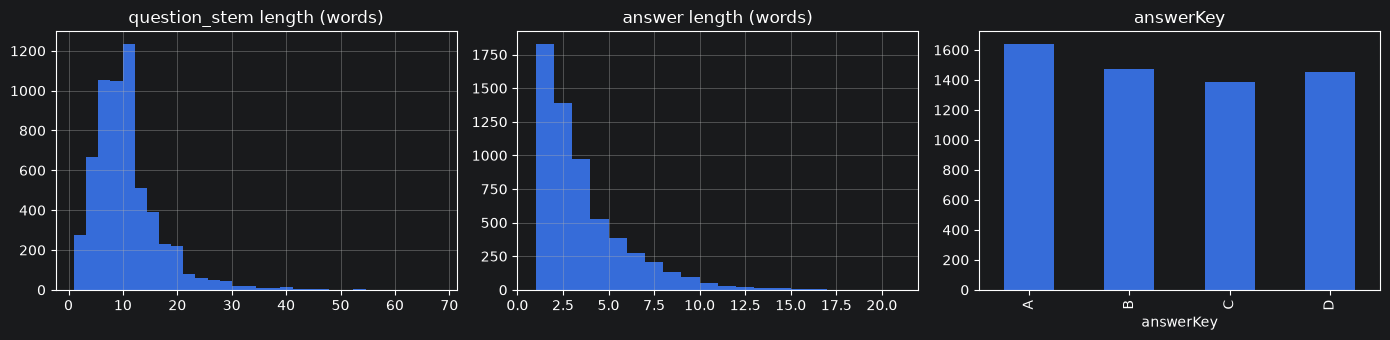

In [7]:
full["stem_words"] = full["question_stem"].str.split().str.len()
full["answer_words"] = full["answer_text"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
full["stem_words"].hist(bins=30, ax=axes[0]); axes[0].set_title("question_stem length (words)")
full["answer_words"].hist(bins=20, ax=axes[1]); axes[1].set_title("answer length (words)")
full["answerKey"].value_counts().sort_index().plot.bar(ax=axes[2]); axes[2].set_title("answerKey")
fig.tight_layout()
full[["stem_words", "answer_words"]].describe()

## 4. How this repo formats a prompt

`OpenBookQA` yields `Example` objects with a ready-to-run `prompt` ending in
`"Reasoning:"`. The model's continuation is the reasoning chain we extract hidden
states from.

In [8]:
from reasoning_trajectories.datasets import OpenBookQA

ds = OpenBookQA(split="validation", limit=5, include_fact=False, shuffle_seed=0)
ex = next(iter(ds))
print(ex.id, "| gold:", ex.answer_key, "| choices:", ex.choice_labels)
print("-" * 80)
print(ex.prompt)

7-278 | gold: A | choices: ['A', 'B', 'C', 'D']
--------------------------------------------------------------------------------
Answer the multiple-choice question below. Reason step by step, then end with a line of exactly the form "Answer: <letter>".
Question: Canyons are rock formations with cliffs that
A. take a long time to produce
B. have sharks in the water
C. are very narrow and shallow
D. are billions of years old

Reasoning:


In [9]:
# with the gold science fact prepended (config 'additional')
ex_fact = next(iter(OpenBookQA(split="validation", hf_config="additional", limit=1, include_fact=True, shuffle_seed=0)))
print(ex_fact.prompt)

Answer the multiple-choice question below. Reason step by step, then end with a line of exactly the form "Answer: <letter>".
Fact: a canyon forming occurs over a period of millions of years
Question: Canyons are rock formations with cliffs that
A. take a long time to produce
B. have sharks in the water
C. are very narrow and shallow
D. are billions of years old

Reasoning:


## 5. Rough prompt token counts

Optional, needs `transformers` and access to the tokenizer. Tells you how much
context each chain starts from before generation.

In [10]:
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("meta-llama/Meta-Llama-3.1-8B")
    lens = [len(tok(e.prompt).input_ids) for e in OpenBookQA(split="validation", limit=200, shuffle_seed=0)]
    print(pd.Series(lens).describe())
except Exception as e:
    print("skipped (tokenizer unavailable):", e)

skipped (tokenizer unavailable): You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/meta-llama/Meta-Llama-3.1-8B.
401 Client Error. (Request ID: Root=1-6a981341-7ac9c9df2faa97723f742235;6bed708b-34db-4460-ba95-f233ab78818a)

Cannot access gated repo for url https://huggingface.co/meta-llama/Meta-Llama-3.1-8B/resolve/main/config.json.
Access to model meta-llama/Llama-3.1-8B is restricted. You must have access to it and be authenticated to access it. Please log in.


### Next steps

- Run an extraction: `python ../scripts/run_extraction.py --config ../configs/default.yaml`
- Then explore trajectories under `../studies/hidden_state_trajectories/`